# Heartbeat PCG Classification -- Streamlined Notebook (v2)

This replaces the earlier exploratory notebook, which grew large across
many experiments: a plain 2D CNN, a two-stage (Normal/Abnormal then
type) pipeline, and several YAMNet variants (pooled head, regularized
BiGRU, Conv1D+GRU hybrid).

**Result of that exploration**: the pooled YAMNet head (frozen YAMNet +
small dense classifier, Extra_Systole class weight reduced from 3.67 to
2.57) was the most consistently strong performer across repeated runs
(avg ~75% accuracy, ~0.28 Extra_Systole f1) -- better and more stable
than the plain CNN, the two-stage pipeline, and the more complex
sequential YAMNet variants, none of which beat it once properly
repeated. Extra_Systole remains the weak point across every architecture
tested, consistent with it having only 109 training files -- a data
limitation, not an architecture one.

This notebook contains only what's needed to reproduce and use that
model going forward.

## 0. Check GPU is active

In [1]:
import tensorflow as tf
print("TensorFlow version:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices('GPU'))

TensorFlow version: 2.20.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 1. Get your data into Colab

Upload a zip of `split_dataset/` + `noise_clips/`.

In [ ]:
from google.colab import files
uploaded = files.upload()
ZIP_NAME = list(uploaded.keys())[0]
print("Uploaded:", ZIP_NAME)

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
ZIP_NAME = "/content/drive/MyDrive/heart_project/heart_project_data.zip"  # adjust path

In [4]:
import zipfile, os

EXTRACT_DIR = "/content/heart_project"
os.makedirs(EXTRACT_DIR, exist_ok=True)

with zipfile.ZipFile(ZIP_NAME, 'r') as zf:
    zf.extractall(EXTRACT_DIR)

# Auto-detect split_dataset/ and noise_clips/ wherever they landed
found = False
for root, dirs, files_ in os.walk(EXTRACT_DIR):
    if 'split_dataset' in dirs and 'noise_clips' in dirs:
        os.chdir(root)
        found = True
        break

if not found:
    print("WARNING: could not find split_dataset/ and noise_clips/ together. "
          "Run: !find /content/heart_project -maxdepth 3")
else:
    print("Working directory:", os.getcwd())
    print("Contents:", os.listdir())

Working directory: /content/heart_project/heart_project_data
Contents: ['split_dataset', 'noise_clips']


## 2. Write the shared utility modules

In [5]:
%%writefile spectrogram_utils.py
import numpy as np
import librosa
from scipy.signal import butter, sosfiltfilt

# --- SHARED CONFIG -- keep everything in the project pointed at this file ---
TARGET_SR = 16000
CHUNK_DURATION = 3          # seconds, matches step 1 chunking
N_FFT = 1024
HOP_LENGTH = 256
N_MELS = 64
FMAX = 800                  # PCG diagnostic content lives under ~600-800Hz

EXPECTED_SAMPLES = TARGET_SR * CHUNK_DURATION
N_FRAMES = 1 + EXPECTED_SAMPLES // HOP_LENGTH

# Heart sound diagnostic content lives in ~20-800Hz. Filtering this
# consistently on EVERY signal (real chunks AND noise clips, before any
# augmentation) removes clearly out-of-band noise/hiss/drift for free.
# It does NOT remove noise that overlaps this band (voices, rumble, fabric
# rustle) -- that's what noise-mixing augmentation is for. The two are
# complementary, not redundant.
BANDPASS_LOW_HZ = 20
BANDPASS_HIGH_HZ = 800
BANDPASS_ORDER = 4

_bandpass_sos_cache = {}

# --- Despike settings ---
# Targets isolated, single-sample-to-a-few-sample digital glitches (an
# instantaneous jump to near full-scale with quiet neighbors on both
# sides) -- distinct from genuine sustained loud/clipped audio, which
# spans many consecutive samples with a smooth attack/decay and is left
# untouched.
DESPIKE_THRESHOLD = 0.95      # near full-scale, in normalized [-1, 1] units
DESPIKE_MAX_RUN = 3           # longer runs are treated as real loud audio
DESPIKE_NEIGHBOR_QUIET = 0.3  # immediate neighbors must be well below this


def despike_glitches(y):
    """Removes isolated near-full-scale digital glitches via linear
    interpolation across the glitch, using its immediate neighbors."""
    y = y.copy()
    abs_y = np.abs(y)
    candidates = np.where(abs_y >= DESPIKE_THRESHOLD)[0]
    if len(candidates) == 0:
        return y

    groups = [[candidates[0]]]
    for idx in candidates[1:]:
        if idx - groups[-1][-1] <= 2:
            groups[-1].append(idx)
        else:
            groups.append([idx])

    for group in groups:
        if len(group) > DESPIKE_MAX_RUN:
            continue  # sustained loud region -- real audio, leave it

        start, end = group[0], group[-1]
        left, right = start - 1, end + 1
        if left < 0 or right >= len(y):
            continue

        # Only treat as a glitch if the audio was genuinely quiet right
        # before and after it -- a real transient's neighbors are still
        # elevated, not near-baseline.
        if abs_y[left] < DESPIKE_NEIGHBOR_QUIET and abs_y[right] < DESPIKE_NEIGHBOR_QUIET:
            y[left:right + 1] = np.linspace(y[left], y[right], right - left + 1)

    return y


def get_bandpass_sos(sr=TARGET_SR):
    """Cached filter coefficients -- avoids recomputing per-call."""
    if sr not in _bandpass_sos_cache:
        nyquist = sr / 2
        low = BANDPASS_LOW_HZ / nyquist
        high = min(BANDPASS_HIGH_HZ / nyquist, 0.99)
        _bandpass_sos_cache[sr] = butter(BANDPASS_ORDER, [low, high],
                                         btype='band', output='sos')
    return _bandpass_sos_cache[sr]


def apply_bandpass(y, sr=TARGET_SR):
    """Zero-phase band-pass filter, applied identically to real audio and
    noise clips alike, so nothing in the pipeline sees unfiltered content."""
    sos = get_bandpass_sos(sr)
    return sosfiltfilt(sos, y).astype(np.float32)


def load_and_filter(filepath, sr=TARGET_SR):
    """The ONE function that should load audio from disk anywhere in this
    project -- loading, resampling, despiking, and band-pass filtering
    all happen here, so training data, noise clips, and visualizations
    can never silently diverge in how they're preprocessed."""
    y, _ = librosa.load(filepath, sr=sr)
    y = despike_glitches(y)       # remove isolated digital glitches first
    return apply_bandpass(y, sr)  # then band-limit to the diagnostic range


def load_fixed_length(source, sr=TARGET_SR, is_array=False):
    """Loads audio (from filepath or an existing array) and forces it to
    exactly CHUNK_DURATION seconds. Re-run this after any augmentation
    that could change length (e.g. time-stretch). Filepath inputs are
    band-pass filtered via load_and_filter; array inputs are assumed to
    already be filtered (e.g. augmented audio that started from a
    filtered source)."""
    if is_array:
        y = source
    else:
        y = load_and_filter(source, sr)

    if len(y) > EXPECTED_SAMPLES:
        y = y[:EXPECTED_SAMPLES]
    elif len(y) < EXPECTED_SAMPLES:
        y = np.pad(y, (0, EXPECTED_SAMPLES - len(y)), mode='constant')
    return y


def audio_to_logmel(y, sr=TARGET_SR):
    """Converts a fixed-length audio array into a fixed-shape log-mel
    spectrogram: (N_MELS, N_FRAMES)."""
    S = librosa.feature.melspectrogram(
        y=y, sr=sr, n_fft=N_FFT, hop_length=HOP_LENGTH,
        n_mels=N_MELS, fmax=FMAX
    )
    S_dB = librosa.power_to_db(S, ref=np.max)

    if S_dB.shape[1] > N_FRAMES:
        S_dB = S_dB[:, :N_FRAMES]
    elif S_dB.shape[1] < N_FRAMES:
        pad_width = N_FRAMES - S_dB.shape[1]
        S_dB = np.pad(S_dB, ((0, 0), (0, pad_width)), mode='constant',
                      constant_values=S_dB.min())

    return S_dB.astype(np.float32)


def wav_to_logmel(filepath):
    """Convenience wrapper: filepath -> fixed-shape log-mel spectrogram."""
    y = load_fixed_length(filepath)
    return audio_to_logmel(y, TARGET_SR)


Writing spectrogram_utils.py


In [6]:
%%writefile augmentation_utils.py
import os
import glob
import random
import numpy as np
import librosa

from spectrogram_utils import TARGET_SR, apply_bandpass, despike_glitches

# Probabilities are applied to EVERY sample identically, regardless of
# class label. This is what structurally prevents "amount of augmentation"
# from becoming a shortcut the model can use instead of real PCG features.
SAFE_AUG_PROB = 0.5     # chance of a generic transform (stretch/volume/faint noise)
NOISE_PROB = 0.3        # chance of real recorded ESP32 noise, independent of the above
SNR_DB_RANGE = (10, 20)

# Pitch-shifting changes the exact frequency band that defines a murmur --
# left out of the default rotation for that reason.
USE_PITCH_SHIFT = False
PITCH_SHIFT_STEPS = 1

_noise_pool_cache = None


def add_faint_noise(y):
    noise = np.random.normal(0, 0.005 * np.amax(np.abs(y)), len(y))
    return y + noise


def fix_length(y, target_length):
    if len(y) > target_length:
        return y[:target_length]
    elif len(y) < target_length:
        return np.pad(y, (0, target_length - len(y)), mode='constant')
    return y


def safe_augment(y, sr):
    """One randomly chosen generic transform -- never real recorded noise."""
    target_length = len(y)
    methods = ["stretch", "volume", "faint_noise"]
    if USE_PITCH_SHIFT:
        methods.append("pitch")
    method = random.choice(methods)

    if method == "stretch":
        rate = np.random.uniform(0.93, 1.07)
        return fix_length(librosa.effects.time_stretch(y, rate=rate), target_length)
    elif method == "volume":
        scale = np.random.uniform(0.7, 1.3)
        return np.clip(y * scale, -1.0, 1.0)
    elif method == "faint_noise":
        return add_faint_noise(y)
    else:
        return librosa.effects.pitch_shift(y, sr=sr, n_steps=PITCH_SHIFT_STEPS)


def load_noise_pool(noise_dir="noise_clips", target_sr=TARGET_SR):
    """Loads and caches your recorded ESP32 noise clips into one pool."""
    global _noise_pool_cache
    if _noise_pool_cache is not None:
        return _noise_pool_cache

    files = glob.glob(os.path.join(noise_dir, "*.wav"))
    if not files:
        return None

    pool = [apply_bandpass(despike_glitches(librosa.load(f, sr=target_sr, mono=True)[0]), target_sr)
            for f in files]
    _noise_pool_cache = np.concatenate(pool)
    return _noise_pool_cache


def get_noise_segment(noise_pool, num_samples):
    if len(noise_pool) < num_samples:
        repeats = int(np.ceil(num_samples / len(noise_pool)))
        noise_pool = np.tile(noise_pool, repeats)
    start = np.random.randint(0, len(noise_pool) - num_samples + 1)
    return noise_pool[start:start + num_samples]


def mix_at_snr(signal, noise, snr_db):
    signal_power = np.mean(signal ** 2)
    noise_power = np.mean(noise ** 2)
    if noise_power == 0:
        return signal
    target_noise_power = signal_power / (10 ** (snr_db / 10))
    scale = np.sqrt(target_noise_power / noise_power)
    mixed = signal + noise * scale
    max_val = np.max(np.abs(mixed))
    if max_val > 1.0:
        mixed = mixed / max_val
    return mixed


def apply_random_augmentation(y, sr, noise_pool=None):
    """The ONE function used everywhere augmentation happens -- training
    generator and visualizations both call this, so behavior can never
    silently diverge between what you see and what the model trains on."""
    if random.random() < SAFE_AUG_PROB:
        y = safe_augment(y, sr)
    if noise_pool is not None and random.random() < NOISE_PROB:
        snr_db = np.random.uniform(*SNR_DB_RANGE)
        noise_seg = get_noise_segment(noise_pool, len(y))
        y = mix_at_snr(y, noise_seg, snr_db)
    return y


Writing augmentation_utils.py


In [7]:
%%writefile train_data_generator.py
import os
import numpy as np
import librosa
from tensorflow.keras.utils import Sequence

from spectrogram_utils import TARGET_SR, load_and_filter, load_fixed_length, audio_to_logmel
from augmentation_utils import apply_random_augmentation, load_noise_pool

TRAIN_DIR = "split_dataset/train"      # raw, unbalanced, unaugmented on disk
CLASSES = ["Normal", "Murmur", "Extra_Systole", "Artifact"]


class PCGSequence(Sequence):
    """Yields (spectrogram_batch, label_batch). With augment=True, every
    sample -- regardless of class -- has the same chance of being time
    -stretched, volume-jittered, or noise-mixed. Nothing here branches on
    class label, by design."""

    def __init__(self, batch_size=32, shuffle=True, augment=True):
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.augment = augment
        self.noise_pool = load_noise_pool() if augment else None

        self.samples = []
        for idx, cls in enumerate(CLASSES):
            class_dir = os.path.join(TRAIN_DIR, cls)
            for f in sorted(os.listdir(class_dir)):
                if f.endswith(".wav"):
                    self.samples.append((os.path.join(class_dir, f), idx))

        self.on_epoch_end()

    def __len__(self):
        return int(np.ceil(len(self.samples) / self.batch_size))

    def on_epoch_end(self):
        if self.shuffle:
            np.random.shuffle(self.samples)

    def __getitem__(self, batch_idx):
        batch = self.samples[batch_idx * self.batch_size:
                              (batch_idx + 1) * self.batch_size]
        X, y = [], []

        for filepath, label in batch:
            audio = load_and_filter(filepath, TARGET_SR)
            audio = load_fixed_length(audio, is_array=True)

            if self.augment:
                audio = apply_random_augmentation(audio, TARGET_SR, self.noise_pool)
                # time-stretch can change length -- re-fix before spectrogram
                audio = load_fixed_length(audio, is_array=True)

            spec = audio_to_logmel(audio, TARGET_SR)
            X.append(spec)
            y.append(label)

        X = np.array(X, dtype=np.float32)[..., np.newaxis]
        y = np.array(y, dtype=np.int64)
        return X, y


def compute_class_weights():
    """Since the train split on disk is NOT balanced (we balance via
    class_weight instead of file duplication), pass this dict to
    model.fit(..., class_weight=...)."""
    from sklearn.utils.class_weight import compute_class_weight

    labels = []
    for idx, cls in enumerate(CLASSES):
        class_dir = os.path.join(TRAIN_DIR, cls)
        n = len([f for f in os.listdir(class_dir) if f.endswith(".wav")])
        labels += [idx] * n

    labels = np.array(labels)
    weights = compute_class_weight(class_weight="balanced",
                                    classes=np.arange(len(CLASSES)), y=labels)
    return {i: w for i, w in enumerate(weights)}


if __name__ == "__main__":
    # Quick sanity check
    seq = PCGSequence(batch_size=8, augment=True)
    X, y = seq[0]
    print(f"Batch shape: {X.shape}, labels: {y}")
    print(f"Class weights: {compute_class_weights()}")


Writing train_data_generator.py


## 3. Import modules and sanity-check

In [8]:
from spectrogram_utils import N_MELS, N_FRAMES, TARGET_SR, load_and_filter, load_fixed_length, audio_to_logmel
from augmentation_utils import apply_random_augmentation, load_noise_pool
from train_data_generator import PCGSequence, compute_class_weights, CLASSES, TRAIN_DIR

sanity_gen = PCGSequence(batch_size=8, augment=True)
X_batch, y_batch = sanity_gen[0]
print("Batch shape:", X_batch.shape)
print("Labels in batch:", y_batch)

class_weights_baseline = compute_class_weights()
print("Baseline class weights:", class_weights_baseline)

Batch shape: (8, 64, 188, 1)
Labels in batch: [1 0 0 0 3 1 3 1]
Baseline class weights: {0: np.float64(0.4476483762597984), 1: np.float64(0.9318181818181818), 2: np.float64(3.6674311926605503), 3: np.float64(2.3794642857142856)}


## 4. Dataset summary

In [9]:
def count_wavs(split_dir):
    counts = {}
    for cls in CLASSES:
        class_dir = os.path.join(split_dir, cls)
        counts[cls] = len([f for f in os.listdir(class_dir) if f.endswith(".wav")]) if os.path.isdir(class_dir) else 0
    return counts

train_counts = count_wavs("split_dataset/train")
val_counts = count_wavs("split_dataset/val")
test_counts = count_wavs("split_dataset/test")

print(f"{'Class':<15}{'Train':>8}{'Val':>8}{'Test':>8}")
for cls in CLASSES:
    print(f"{cls:<15}{train_counts[cls]:>8}{val_counts[cls]:>8}{test_counts[cls]:>8}")
print(f"\nTotal train: {sum(train_counts.values())}, val: {sum(val_counts.values())}, test: {sum(test_counts.values())}")

Class             Train     Val    Test
Normal              893     184     242
Murmur              429      93      84
Extra_Systole       109      29      16
Artifact            168      36      36

Total train: 1599, val: 342, test: 378


## 5. Load YAMNet (frozen feature extractor)

In [10]:
import tensorflow_hub as hub

yamnet_model = hub.load('https://tfhub.dev/google/yamnet/1')

sample_path = os.path.join(TRAIN_DIR, "Normal", sorted(os.listdir(os.path.join(TRAIN_DIR, "Normal")))[0])
sample_audio = load_and_filter(sample_path, TARGET_SR)
sample_audio = load_fixed_length(sample_audio, is_array=True)
waveform = tf.convert_to_tensor(sample_audio, dtype=tf.float32)
scores, embeddings, spectrogram = yamnet_model(waveform)
print("Embeddings shape (num_frames, 1024):", embeddings.shape)

/usr/local/lib/python3.13/dist-packages/tensorflow_hub/__init__.py:61: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import parse_version


Embeddings shape (num_frames, 1024): (6, 1024)


## 6. Training generator (mean-pooled YAMNet embeddings, on-the-fly augmented)

In [11]:
from tensorflow.keras.utils import Sequence
import numpy as np

class YamnetEmbeddingSequence(Sequence):
    def __init__(self, batch_size=32, shuffle=True, augment=True):
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.augment = augment
        self.noise_pool = load_noise_pool() if augment else None

        self.samples = []
        for idx, cls in enumerate(CLASSES):
            class_dir = os.path.join(TRAIN_DIR, cls)
            for f in sorted(os.listdir(class_dir)):
                if f.endswith(".wav"):
                    self.samples.append((os.path.join(class_dir, f), idx))
        self.on_epoch_end()

    def __len__(self):
        return int(np.ceil(len(self.samples) / self.batch_size))

    def on_epoch_end(self):
        if self.shuffle:
            np.random.shuffle(self.samples)

    def __getitem__(self, batch_idx):
        batch = self.samples[batch_idx * self.batch_size:(batch_idx + 1) * self.batch_size]
        X, y = [], []
        for filepath, label in batch:
            audio = load_and_filter(filepath, TARGET_SR)
            audio = load_fixed_length(audio, is_array=True)
            if self.augment:
                audio = apply_random_augmentation(audio, TARGET_SR, self.noise_pool)
                audio = load_fixed_length(audio, is_array=True)
            waveform = tf.convert_to_tensor(audio, dtype=tf.float32)
            _, embeddings, _ = yamnet_model(waveform)
            embedding = tf.reduce_mean(embeddings, axis=0).numpy()
            X.append(embedding)
            y.append(label)
        return np.array(X, dtype=np.float32), np.array(y, dtype=np.int64)


train_gen_yamnet = YamnetEmbeddingSequence(batch_size=32, shuffle=True, augment=True)
print(f"Train batches per epoch: {len(train_gen_yamnet)}")

Train batches per epoch: 50


## 7. Precompute val/test embeddings (never augmented)

In [53]:
def build_yamnet_embeddings(split_dir):
    X, y = [], []
    for class_idx, class_name in enumerate(CLASSES):
        class_dir = os.path.join(split_dir, class_name)
        files_ = sorted(f for f in os.listdir(class_dir) if f.endswith(".wav"))
        print(f"  {class_name}: {len(files_)} files")
        for f in files_:
            audio = load_and_filter(os.path.join(class_dir, f), TARGET_SR)
            audio = load_fixed_length(audio, is_array=True)
            waveform = tf.convert_to_tensor(audio, dtype=tf.float32)
            _, embeddings, _ = yamnet_model(waveform)
            embedding = tf.reduce_mean(embeddings, axis=0).numpy()
            X.append(embedding)
            y.append(class_idx)
    return np.array(X, dtype=np.float32), np.array(y, dtype=np.int64)

print("Building val embeddings...")
X_val_yamnet, y_val_yamnet = build_yamnet_embeddings("split_dataset/val")
print("Building test embeddings...")
X_test_yamnet, y_test_yamnet = build_yamnet_embeddings("split_dataset/test")

print(f"\nX_val_yamnet shape: {X_val_yamnet.shape}")
print(f"X_test_yamnet shape: {X_test_yamnet.shape}")

Building val embeddings...
  Normal: 184 files
  Murmur: 93 files
  Extra_Systole: 29 files
  Artifact: 36 files
Building test embeddings...
  Normal: 242 files
  Murmur: 84 files
  Extra_Systole: 16 files
  Artifact: 36 files

X_val_yamnet shape: (342, 1024)
X_test_yamnet shape: (378, 1024)


## 8. Build the classifier head

In [54]:
from tensorflow.keras import layers, models

def build_yamnet_head(input_dim=1024, num_classes=4):
    inputs = layers.Input(shape=(input_dim,))
    x = layers.Dense(128, activation='relu')(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.4)(x)
    x = layers.Dense(64, activation='relu')(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(num_classes, activation='softmax')(x)
    return models.Model(inputs, outputs)

model_yamnet = build_yamnet_head()
model_yamnet.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model_yamnet.summary()

Model: "functional_9"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_9 (InputLayer)      │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_23 (Dense)                │ (None, 128)            │       131,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_37          │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_30 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_24 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_31 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_25 (Dense)                │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 140,228 (547.77 KB)

 Trainable params: 139,972 (546.77 KB)

 Non-trainable params: 256 (1.00 KB)

## 9. Fresh callbacks, fresh weights (Extra_Systole reduced to counter overcorrection), train

In [55]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

callbacks_yamnet = [
    EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4, min_lr=1e-6),
    ModelCheckpoint('best_yamnet_head.keras', monitor='val_loss', save_best_only=True),
]

class_weights_yamnet = compute_class_weights()
class_weights_yamnet[2] *= 0.7   # Extra_Systole: 3.67 -> ~2.57
print("Class weights used:", class_weights_yamnet)

history_yamnet = model_yamnet.fit(
    train_gen_yamnet,
    validation_data=(X_val_yamnet, y_val_yamnet),
    epochs=40,
    class_weight=class_weights_yamnet,
    callbacks=callbacks_yamnet,
)

Class weights used: {0: np.float64(0.4476483762597984), 1: np.float64(0.9318181818181818), 2: np.float64(2.567201834862385), 3: np.float64(2.3794642857142856)}
Epoch 1/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 22s 392ms/step - accuracy: 0.4459 - loss: 1.1633 - val_accuracy: 0.6637 - val_loss: 1.1042 - learning_rate: 0.0010
Epoch 2/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 36s 327ms/step - accuracy: 0.5053 - loss: 0.9080 - val_accuracy: 0.6316 - val_loss: 1.0066 - learning_rate: 0.0010
Epoch 3/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 17s 331ms/step - accuracy: 0.5422 - loss: 0.8760 - val_accuracy: 0.5877 - val_loss: 0.9853 - learning_rate: 0.0010
Epoch 4/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 17s 335ms/step - accuracy: 0.5866 - loss: 0.8246 - val_accuracy: 0.6228 - val_loss: 0.8979 - learning_rate: 0.0010
Epoch 5/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 16s 320ms/step - accuracy: 0.5647 - loss: 0.8103 - val_accuracy: 0.6170 - val_loss: 0.8967 - learning_rate: 0.0010
Epoch 6/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 16s 319ms/step - accuracy: 0.6010 - l

## 10. Plot training curves

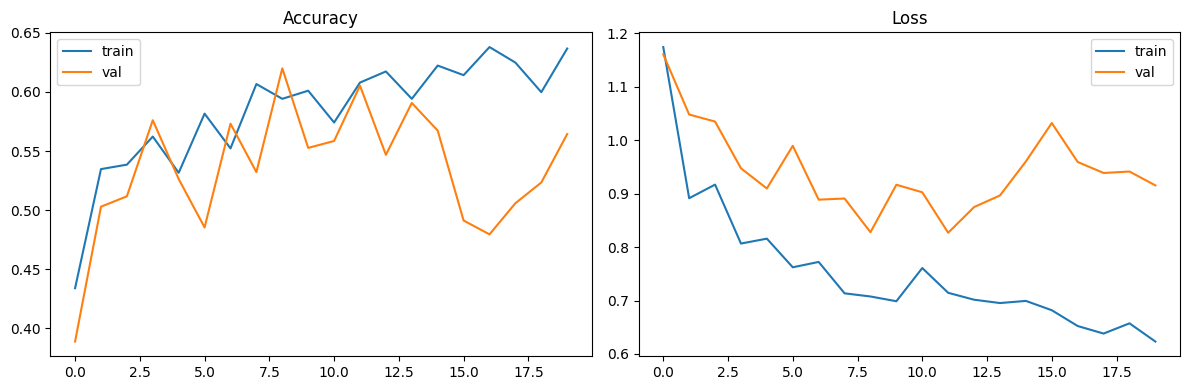

In [33]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history_yamnet.history['accuracy'], label='train')
axes[0].plot(history_yamnet.history['val_accuracy'], label='val')
axes[0].set_title('Accuracy'); axes[0].legend()
axes[1].plot(history_yamnet.history['loss'], label='train')
axes[1].plot(history_yamnet.history['val_loss'], label='val')
axes[1].set_title('Loss'); axes[1].legend()
plt.tight_layout()
plt.show()

## 11. Confirm performance -- test set evaluation

12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.7751 - loss: 0.8141
Test accuracy: 0.7751
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step

Classification report:
               precision    recall  f1-score   support

       Normal       0.84      0.85      0.85       242
       Murmur       0.76      0.61      0.68        84
Extra_Systole       0.23      0.31      0.26        16
     Artifact       0.70      0.89      0.78        36

     accuracy                           0.78       378
    macro avg       0.63      0.66      0.64       378
 weighted avg       0.79      0.78      0.78       378



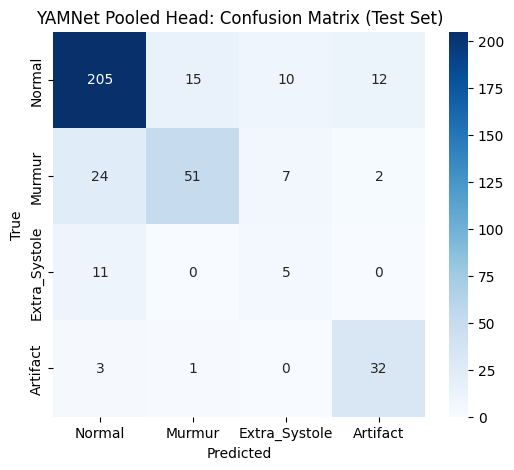


Expected range from prior repeated runs: accuracy 0.70-0.78, Extra_Systole f1 0.20-0.30.
If this run falls well outside that range, note it -- may be worth an extra confirmation run.


In [56]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

test_loss, test_acc = model_yamnet.evaluate(X_test_yamnet, y_test_yamnet)
print(f"Test accuracy: {test_acc:.4f}")

y_pred = np.argmax(model_yamnet.predict(X_test_yamnet), axis=1)
print("\nClassification report:")
print(classification_report(y_test_yamnet, y_pred, target_names=CLASSES))

cm = confusion_matrix(y_test_yamnet, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=CLASSES, yticklabels=CLASSES)
plt.xlabel('Predicted'); plt.ylabel('True')
plt.title('YAMNet Pooled Head: Confusion Matrix (Test Set)')
plt.show()

print("\nExpected range from prior repeated runs: accuracy 0.70-0.78, Extra_Systole f1 0.20-0.30.")
print("If this run falls well outside that range, note it -- may be worth an extra confirmation run.")

## 12. Save the model

In [ ]:
model_yamnet.save("pcg_yamnet_final.keras")
print("Saved. Download it or copy to your mounted Drive folder.")

# import shutil
# shutil.copy("pcg_yamnet_final.keras", "/content/drive/MyDrive/heart_project/pcg_yamnet_final.keras")

## 13. Improve the model: Focal Loss instead of plain weighted cross-entropy

Plain class-weighting tells the model "mistakes on this class cost more," uniformly across every example of that class. Focal loss adds a second ingredient: it automatically down-weights examples the model already gets confidently right, and concentrates learning on the ones it's still getting wrong. YAMNet itself stays frozen -- only the loss function used to train the classifier head changes.

In [ ]:
import tensorflow as tf

def sparse_categorical_focal_loss(alpha, gamma=2.0):
    """alpha: per-class weight list/array (same role as class_weight).
    gamma: focusing parameter -- higher means more focus on hard examples."""
    alpha = tf.constant(alpha, dtype=tf.float32)

    def loss_fn(y_true, y_pred):
        y_true = tf.cast(y_true, tf.int32)
        y_pred = tf.clip_by_value(y_pred, 1e-7, 1.0 - 1e-7)
        num_classes = tf.shape(y_pred)[-1]
        y_true_one_hot = tf.one_hot(y_true, depth=num_classes)

        cross_entropy = -y_true_one_hot * tf.math.log(y_pred)
        p_t = tf.reduce_sum(y_true_one_hot * y_pred, axis=-1, keepdims=True)
        modulating_factor = tf.pow(1.0 - p_t, gamma)

        alpha_t = tf.reduce_sum(y_true_one_hot * alpha, axis=-1, keepdims=True)
        loss = alpha_t * modulating_factor * tf.reduce_sum(cross_entropy, axis=-1, keepdims=True)
        return tf.reduce_mean(loss)

    return loss_fn


# Reuse the same per-class weighting we already validated, now as alpha
focal_alpha = compute_class_weights()
focal_alpha[2] *= 0.7   # keep the same Extra_Systole adjustment as before
focal_alpha_list = [focal_alpha[i] for i in range(len(CLASSES))]
print("Focal loss alpha (per-class):", focal_alpha_list)

Focal loss alpha (per-class): [np.float64(0.4476483762597984), np.float64(0.9318181818181818), np.float64(2.567201834862385), np.float64(2.3794642857142856)]


In [ ]:
model_yamnet_focal = build_yamnet_head()
model_yamnet_focal.compile(
    optimizer='adam',
    loss=sparse_categorical_focal_loss(alpha=focal_alpha_list, gamma=2.0),
    metrics=['accuracy']
)
model_yamnet_focal.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │       131,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 140,228 (547.77 KB)

 Trainable params: 139,972 (546.77 KB)

 Non-trainable params: 256 (1.00 KB)

In [ ]:
callbacks_focal = [
    EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4, min_lr=1e-6),
    ModelCheckpoint('best_yamnet_focal.keras', monitor='val_loss', save_best_only=True),
]

history_focal = model_yamnet_focal.fit(
    train_gen_yamnet,
    validation_data=(X_val_yamnet, y_val_yamnet),
    epochs=40,
    callbacks=callbacks_focal,
)

Epoch 1/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 29s 438ms/step - accuracy: 0.4540 - loss: 0.7327 - val_accuracy: 0.6930 - val_loss: 0.5241 - learning_rate: 0.0010
Epoch 2/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 28s 555ms/step - accuracy: 0.5153 - loss: 0.5550 - val_accuracy: 0.6637 - val_loss: 0.4562 - learning_rate: 0.0010
Epoch 3/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 18s 363ms/step - accuracy: 0.5216 - loss: 0.4931 - val_accuracy: 0.7105 - val_loss: 0.4557 - learning_rate: 0.0010
Epoch 4/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 20s 398ms/step - accuracy: 0.5322 - loss: 0.4654 - val_accuracy: 0.6491 - val_loss: 0.4048 - learning_rate: 0.0010
Epoch 5/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 19s 371ms/step - accuracy: 0.5472 - loss: 0.4267 - val_accuracy: 0.6754 - val_loss: 0.3917 - learning_rate: 0.0010
Epoch 6/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 18s 350ms/step - accuracy: 0.5641 - loss: 0.4091 - val_accuracy: 0.5848 - val_loss: 0.3559 - learning_rate: 0.0010
Epoch 7/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 18s 359ms/step - accuracy: 0.5441 - loss: 0.

12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 0.6693 - loss: 0.2491
Focal loss model test accuracy: 0.6693
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step

Classification report (focal loss):
               precision    recall  f1-score   support

       Normal       0.86      0.64      0.73       242
       Murmur       0.67      0.69      0.68        84
Extra_Systole       0.14      0.50      0.21        16
     Artifact       0.63      0.92      0.75        36

     accuracy                           0.67       378
    macro avg       0.57      0.69      0.59       378
 weighted avg       0.76      0.67      0.70       378



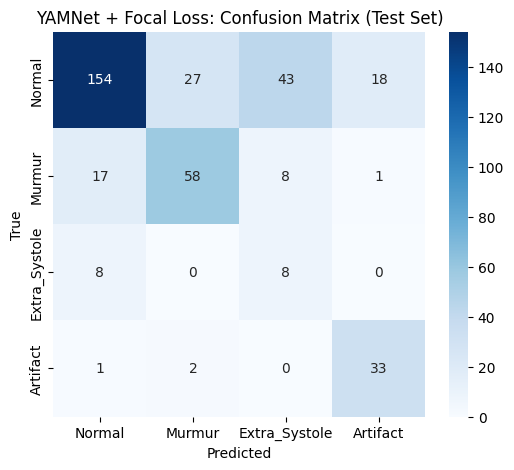


Compare against the plain-weighted baseline: accuracy ~0.70-0.78, Extra_Systole f1 ~0.20-0.30.


In [ ]:
test_loss_focal, test_acc_focal = model_yamnet_focal.evaluate(X_test_yamnet, y_test_yamnet)
print(f"Focal loss model test accuracy: {test_acc_focal:.4f}")

y_pred_focal = np.argmax(model_yamnet_focal.predict(X_test_yamnet), axis=1)
print("\nClassification report (focal loss):")
print(classification_report(y_test_yamnet, y_pred_focal, target_names=CLASSES))

cm_focal = confusion_matrix(y_test_yamnet, y_pred_focal)
plt.figure(figsize=(6, 5))
sns.heatmap(cm_focal, annot=True, fmt='d', cmap='Blues', xticklabels=CLASSES, yticklabels=CLASSES)
plt.xlabel('Predicted'); plt.ylabel('True')
plt.title('YAMNet + Focal Loss: Confusion Matrix (Test Set)')
plt.show()

print("\nCompare against the plain-weighted baseline: accuracy ~0.70-0.78, Extra_Systole f1 ~0.20-0.30.")

## 14. Deeper Custom CNN

Since we're targeting a laptop, not a microcontroller, model size is no
longer a constraint. This CNN has 4 conv blocks (32-64-128-256 filters,
two conv layers per block) instead of the original 3-block, single-conv
design -- more capacity to find subtle patterns, balanced with L2
regularization and stronger dropout to control overfitting on our still
-small dataset (dataset size, not model size, is the real limiter here).

In [57]:
def build_split(split_dir, split_name):
    print(f"Processing '{split_name}' split from '{split_dir}'...")
    X, y = [], []
    for class_idx, class_name in enumerate(CLASSES):
        class_dir = os.path.join(split_dir, class_name)
        files_ = sorted(f for f in os.listdir(class_dir) if f.endswith(".wav"))
        print(f"  {class_name}: {len(files_)} files")
        for f in files_:
            spec = wav_to_logmel(os.path.join(class_dir, f))
            X.append(spec)
            y.append(class_idx)
    X = np.array(X, dtype=np.float32)[..., np.newaxis]
    y = np.array(y, dtype=np.int64)
    print(f"  '{split_name}' shape: X={X.shape}, y={y.shape}")
    return X, y

from spectrogram_utils import wav_to_logmel

X_val, y_val = build_split("split_dataset/val", "val")
X_test, y_test = build_split("split_dataset/test", "test")

Processing 'val' split from 'split_dataset/val'...
  Normal: 184 files
  Murmur: 93 files
  Extra_Systole: 29 files
  Artifact: 36 files
  'val' shape: X=(342, 64, 188, 1), y=(342,)
Processing 'test' split from 'split_dataset/test'...
  Normal: 242 files
  Murmur: 84 files
  Extra_Systole: 16 files
  Artifact: 36 files
  'test' shape: X=(378, 64, 188, 1), y=(378,)


In [58]:
from tensorflow.keras.regularizers import l2

def build_deep_cnn(input_shape=(64, 188, 1), num_classes=4, l2_reg=1e-4):
    inputs = layers.Input(shape=input_shape)

    x = layers.Conv2D(32, 3, padding='same', kernel_regularizer=l2(l2_reg), activation='relu')(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.Conv2D(32, 3, padding='same', kernel_regularizer=l2(l2_reg), activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D(2)(x)
    x = layers.Dropout(0.2)(x)

    x = layers.Conv2D(64, 3, padding='same', kernel_regularizer=l2(l2_reg), activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Conv2D(64, 3, padding='same', kernel_regularizer=l2(l2_reg), activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D(2)(x)
    x = layers.Dropout(0.25)(x)

    x = layers.Conv2D(128, 3, padding='same', kernel_regularizer=l2(l2_reg), activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Conv2D(128, 3, padding='same', kernel_regularizer=l2(l2_reg), activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D(2)(x)
    x = layers.Dropout(0.3)(x)

    x = layers.Conv2D(256, 3, padding='same', kernel_regularizer=l2(l2_reg), activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D(2)(x)
    x = layers.Dropout(0.35)(x)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation='relu', kernel_regularizer=l2(l2_reg))(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.4)(x)
    outputs = layers.Dense(num_classes, activation='softmax')(x)

    return models.Model(inputs, outputs)

model_deep_cnn = build_deep_cnn()
model_deep_cnn.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model_deep_cnn.summary()

Model: "functional_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_10 (InputLayer)     │ (None, 64, 188, 1)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_28 (Conv2D)              │ (None, 64, 188, 32)    │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_38          │ (None, 64, 188, 32)    │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_29 (Conv2D)              │ (None, 64, 188, 32)    │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_39          │ (None, 64, 188, 32)    │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_16 (MaxPooling2D) │ (None, 32, 94, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_32 (Dropout)            │ (None, 32, 94, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_30 (Conv2D)              │ (None, 32, 94, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_40          │ (None, 32, 94, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_31 (Conv2D)              │ (None, 32, 94, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_41          │ (None, 32, 94, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_17 (MaxPooling2D) │ (None, 16, 47, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_33 (Dropout)            │ (None, 16, 47, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_32 (Conv2D)              │ (None, 16, 47, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_42          │ (None, 16, 47, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_33 (Conv2D)              │ (None, 16, 47, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_43          │ (None, 16, 47, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_18 (MaxPooling2D) │ (None, 8, 23, 128)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_34 (Dropout)            │ (None, 8, 23, 128)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_34 (Conv2D)              │ (None, 8, 23, 256)     │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_44          │ (None, 8, 23, 256)     │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 618,340 (2.36 MB)

 Trainable params: 616,676 (2.35 MB)

 Non-trainable params: 1,664 (6.50 KB)

In [59]:
callbacks_deep_cnn = [
    EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4, min_lr=1e-6),
    ModelCheckpoint('best_deep_cnn.keras', monitor='val_loss', save_best_only=True),
]

class_weights_deep = compute_class_weights()
print("Class weights:", class_weights_deep)

train_gen_deep = PCGSequence(batch_size=32, shuffle=True, augment=True)

history_deep_cnn = model_deep_cnn.fit(
    train_gen_deep,
    validation_data=(X_val, y_val),
    epochs=40,
    class_weight=class_weights_deep,
    callbacks=callbacks_deep_cnn,
)

Class weights: {0: np.float64(0.4476483762597984), 1: np.float64(0.9318181818181818), 2: np.float64(3.6674311926605503), 3: np.float64(2.3794642857142856)}


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 49s 705ms/step - accuracy: 0.4009 - loss: 1.3778 - val_accuracy: 0.2778 - val_loss: 3.2976 - learning_rate: 0.0010
Epoch 2/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 62s 492ms/step - accuracy: 0.4603 - loss: 1.1602 - val_accuracy: 0.3333 - val_loss: 4.7208 - learning_rate: 0.0010
Epoch 3/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 23s 451ms/step - accuracy: 0.5153 - loss: 0.8974 - val_accuracy: 0.4386 - val_loss: 1.6240 - learning_rate: 0.0010
Epoch 4/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 25s 501ms/step - accuracy: 0.5397 - loss: 0.9293 - val_accuracy: 0.6257 - val_loss: 0.9193 - learning_rate: 0.0010
Epoch 5/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 24s 475ms/step - accuracy: 0.5897 - loss: 0.8324 - val_accuracy: 0.7398 - val_loss: 1.0418 - learning_rate: 0.0010
Epoch 6/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 40s 458ms/step - accuracy: 0.6048 - loss: 0.7310 - val_accuracy: 0.6374 - val_loss: 1.0758 - learning_rate: 0.0010
Epoch 7/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 24s 475ms/step - accuracy: 0.6260 - loss: 0.

12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 145ms/step - accuracy: 0.6667 - loss: 0.8895
Deep CNN test accuracy: 0.6667
12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 78ms/step

Classification report:
               precision    recall  f1-score   support

       Normal       0.79      0.73      0.76       242
       Murmur       0.62      0.61      0.61        84
Extra_Systole       0.02      0.06      0.03        16
     Artifact       1.00      0.64      0.78        36

     accuracy                           0.67       378
    macro avg       0.61      0.51      0.55       378
 weighted avg       0.74      0.67      0.70       378



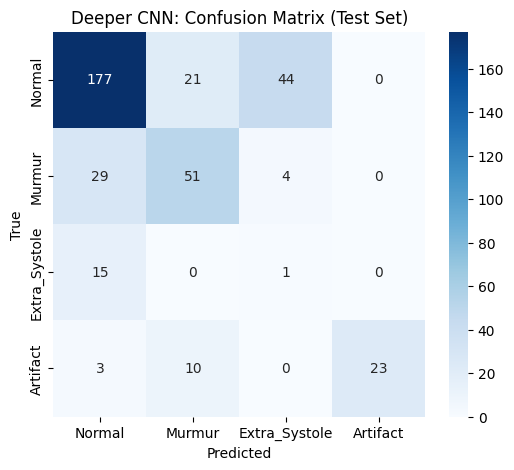


Compare against YAMNet baseline: accuracy ~0.70-0.78, Extra_Systole f1 ~0.20-0.30.


In [60]:
test_loss_deep, test_acc_deep = model_deep_cnn.evaluate(X_test, y_test)
print(f"Deep CNN test accuracy: {test_acc_deep:.4f}")

y_pred_deep = np.argmax(model_deep_cnn.predict(X_test), axis=1)
print("\nClassification report:")
print(classification_report(y_test, y_pred_deep, target_names=CLASSES))

cm_deep = confusion_matrix(y_test, y_pred_deep)
plt.figure(figsize=(6, 5))
sns.heatmap(cm_deep, annot=True, fmt='d', cmap='Blues', xticklabels=CLASSES, yticklabels=CLASSES)
plt.xlabel('Predicted'); plt.ylabel('True')
plt.title('Deeper CNN: Confusion Matrix (Test Set)')
plt.show()

print("\nCompare against YAMNet baseline: accuracy ~0.70-0.78, Extra_Systole f1 ~0.20-0.30.")

## 15. Ensemble: Deeper CNN + YAMNet

Combines predicted probabilities from both models. The deeper CNN excels
on Normal/Murmur/Artifact but has a confirmed 0% recall on Extra_Systole
across 3 repeats; YAMNet is weaker overall but the only model that
reliably gets some signal on Extra_Systole. Averaging their probabilities
tests whether this complementary weakness/strength pattern actually
helps in combination.

Alignment check passed -- y_test and y_test_yamnet match exactly.
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
 ENSEMBLE (Deep CNN + YAMNet, equal weight)
               precision    recall  f1-score   support

       Normal       0.83      0.85      0.84       242
       Murmur       0.71      0.68      0.70        84
Extra_Systole       0.07      0.06      0.07        16
     Artifact       0.87      0.92      0.89        36

     accuracy                           0.78       378
    macro avg       0.62      0.63      0.62       378
 weighted avg       0.78      0.78      0.78       378



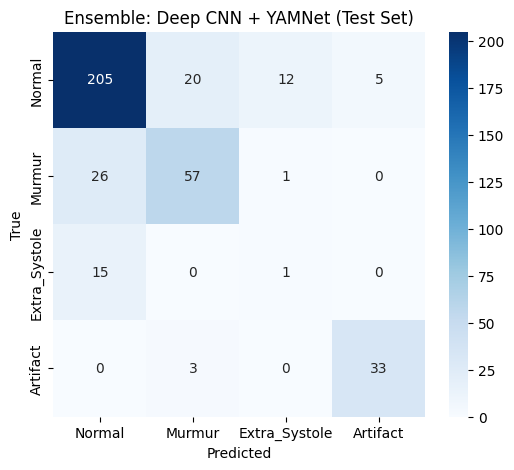


Ensemble overall accuracy: 0.7831
Compare: Deep CNN alone ~0.70-0.82, YAMNet alone ~0.70-0.78


In [61]:
# Sanity check: X_test and X_test_yamnet must represent the same files
# in the same order, or averaging their predictions is meaningless.
assert np.array_equal(y_test, y_test_yamnet), "Test set order mismatch between CNN and YAMNet arrays!"
print("Alignment check passed -- y_test and y_test_yamnet match exactly.")

probs_cnn = model_deep_cnn.predict(X_test)
probs_yamnet = model_yamnet.predict(X_test_yamnet)

# Simple equal-weight average first
ensemble_probs = (probs_cnn + probs_yamnet) / 2
ensemble_preds = np.argmax(ensemble_probs, axis=1)

print("=" * 55)
print(" ENSEMBLE (Deep CNN + YAMNet, equal weight)")
print("=" * 55)
print(classification_report(y_test, ensemble_preds, target_names=CLASSES))

cm_ensemble = confusion_matrix(y_test, ensemble_preds)
plt.figure(figsize=(6, 5))
sns.heatmap(cm_ensemble, annot=True, fmt='d', cmap='Blues', xticklabels=CLASSES, yticklabels=CLASSES)
plt.xlabel('Predicted'); plt.ylabel('True')
plt.title('Ensemble: Deep CNN + YAMNet (Test Set)')
plt.show()

ensemble_acc = np.mean(ensemble_preds == y_test)
print(f"\nEnsemble overall accuracy: {ensemble_acc:.4f}")
print("Compare: Deep CNN alone ~0.70-0.82, YAMNet alone ~0.70-0.78")

## 16. Reweighted Ensemble

Equal-weight averaging may let the deep CNN's more confident (but
sometimes wrong) predictions dominate over YAMNet's more modest ones --
a known ensembling issue. This tests several weightings favoring YAMNet,
using the same predictions already computed in Section 15 (no retraining
needed).

In [62]:
for yamnet_weight in [0.5, 0.6, 0.7, 0.8]:
    cnn_weight = 1 - yamnet_weight
    weighted_probs = yamnet_weight * probs_yamnet + cnn_weight * probs_cnn
    weighted_preds = np.argmax(weighted_probs, axis=1)

    acc = np.mean(weighted_preds == y_test)
    report = classification_report(y_test, weighted_preds, target_names=CLASSES, output_dict=True)
    es_f1 = report["Extra_Systole"]["f1-score"]
    es_precision = report["Extra_Systole"]["precision"]
    es_recall = report["Extra_Systole"]["recall"]

    print(f"YAMNet weight {yamnet_weight} / CNN weight {cnn_weight:.1f}: "
          f"accuracy={acc:.4f}, Extra_Systole precision={es_precision:.2f}, "
          f"recall={es_recall:.2f}, f1={es_f1:.2f}")

YAMNet weight 0.5 / CNN weight 0.5: accuracy=0.7831, Extra_Systole precision=0.07, recall=0.06, f1=0.07
YAMNet weight 0.6 / CNN weight 0.4: accuracy=0.7937, Extra_Systole precision=0.12, recall=0.06, f1=0.08
YAMNet weight 0.7 / CNN weight 0.3: accuracy=0.7884, Extra_Systole precision=0.17, recall=0.06, f1=0.09
YAMNet weight 0.8 / CNN weight 0.2: accuracy=0.7831, Extra_Systole precision=0.25, recall=0.12, f1=0.17


In [63]:
for yamnet_weight in [0.9, 0.95, 1.0]:
    cnn_weight = 1 - yamnet_weight
    weighted_probs = yamnet_weight * probs_yamnet + cnn_weight * probs_cnn
    weighted_preds = np.argmax(weighted_probs, axis=1)

    acc = np.mean(weighted_preds == y_test)
    report = classification_report(y_test, weighted_preds, target_names=CLASSES, output_dict=True)
    es_f1 = report["Extra_Systole"]["f1-score"]
    es_precision = report["Extra_Systole"]["precision"]
    es_recall = report["Extra_Systole"]["recall"]

    print(f"YAMNet weight {yamnet_weight} / CNN weight {cnn_weight:.2f}: "
          f"accuracy={acc:.4f}, Extra_Systole precision={es_precision:.2f}, "
          f"recall={es_recall:.2f}, f1={es_f1:.2f}")

YAMNet weight 0.9 / CNN weight 0.10: accuracy=0.7884, Extra_Systole precision=0.27, recall=0.19, f1=0.22
YAMNet weight 0.95 / CNN weight 0.05: accuracy=0.7778, Extra_Systole precision=0.28, recall=0.31, f1=0.29
YAMNet weight 1.0 / CNN weight 0.00: accuracy=0.7751, Extra_Systole precision=0.23, recall=0.31, f1=0.26


 FINAL ENSEMBLE (0.95 YAMNet / 0.05 CNN)
               precision    recall  f1-score   support

       Normal       0.83      0.85      0.84       242
       Murmur       0.75      0.61      0.67        84
Extra_Systole       0.28      0.31      0.29        16
     Artifact       0.71      0.89      0.79        36

     accuracy                           0.78       378
    macro avg       0.64      0.66      0.65       378
 weighted avg       0.78      0.78      0.78       378



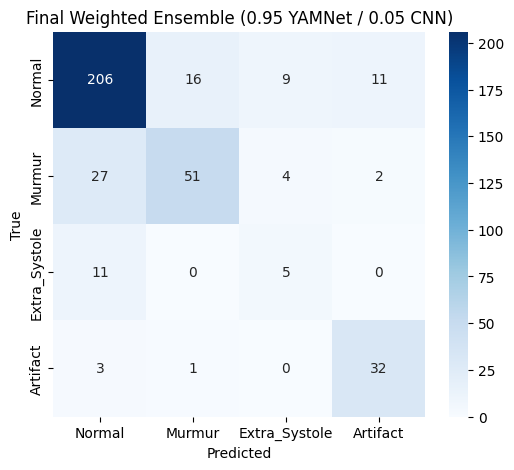


Overall accuracy: 0.7778


In [64]:
final_yamnet_weight = 0.95
final_cnn_weight = 1 - final_yamnet_weight

final_probs = final_yamnet_weight * probs_yamnet + final_cnn_weight * probs_cnn
final_preds = np.argmax(final_probs, axis=1)

print("=" * 55)
print(f" FINAL ENSEMBLE ({final_yamnet_weight} YAMNet / {final_cnn_weight:.2f} CNN)")
print("=" * 55)
print(classification_report(y_test, final_preds, target_names=CLASSES))

cm_final = confusion_matrix(y_test, final_preds)
plt.figure(figsize=(6, 5))
sns.heatmap(cm_final, annot=True, fmt='d', cmap='Blues', xticklabels=CLASSES, yticklabels=CLASSES)
plt.xlabel('Predicted'); plt.ylabel('True')
plt.title('Final Weighted Ensemble (0.95 YAMNet / 0.05 CNN)')
plt.show()

print(f"\nOverall accuracy: {np.mean(final_preds == y_test):.4f}")

## 17. Mixed Two-Stage: Deep CNN (binary) + YAMNet (abnormal type)

Stage 1: deep CNN decides Normal vs Abnormal.
Stage 2: only for cases Stage 1 flags abnormal, YAMNet's classifier head
decides Murmur/Extra_Systole/Artifact -- unlike our earlier two-stage
attempt, Stage 2 here uses the model that's actually shown real signal
on Extra_Systole, not a second CNN.

In [65]:
from sklearn.utils.class_weight import compute_class_weight

y_val_binary = (y_val > 0).astype(np.int64)
y_test_binary = (y_test > 0).astype(np.int64)

binary_labels = []
for idx, cls in enumerate(CLASSES):
    class_dir = os.path.join(TRAIN_DIR, cls)
    n = len([f for f in os.listdir(class_dir) if f.endswith(".wav")])
    label = 0 if cls == "Normal" else 1
    binary_labels += [label] * n
binary_labels = np.array(binary_labels)

stage1_class_weights = compute_class_weight(
    class_weight="balanced", classes=np.array([0, 1]), y=binary_labels)
stage1_class_weights = {i: w for i, w in enumerate(stage1_class_weights)}
print("Stage 1 (binary) class weights:", stage1_class_weights)


class BinaryLabelWrapper(Sequence):
    def __init__(self, base_sequence):
        self.base = base_sequence
    def __len__(self):
        return len(self.base)
    def on_epoch_end(self):
        self.base.on_epoch_end()
    def __getitem__(self, idx):
        X, y = self.base[idx]
        return X, (y > 0).astype(np.int64)


train_gen_stage1 = BinaryLabelWrapper(PCGSequence(batch_size=32, shuffle=True, augment=True))
print(f"Stage 1 train batches per epoch: {len(train_gen_stage1)}")

Stage 1 (binary) class weights: {0: np.float64(0.8952967525195968), 1: np.float64(1.1324362606232294)}
Stage 1 train batches per epoch: 50


In [66]:
def build_deep_cnn_binary(input_shape=(64, 188, 1), l2_reg=1e-4):
    return build_deep_cnn(input_shape=input_shape, num_classes=2, l2_reg=l2_reg)

model_stage1_deep = build_deep_cnn_binary()
model_stage1_deep.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

callbacks_stage1_deep = [
    EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4, min_lr=1e-6),
    ModelCheckpoint('best_stage1_deep_binary.keras', monitor='val_loss', save_best_only=True),
]

history_stage1_deep = model_stage1_deep.fit(
    train_gen_stage1,
    validation_data=(X_val, y_val_binary),
    epochs=40,
    class_weight=stage1_class_weights,
    callbacks=callbacks_stage1_deep,
)

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 62s 859ms/step - accuracy: 0.6654 - loss: 0.8365 - val_accuracy: 0.4561 - val_loss: 2.0610 - learning_rate: 0.0010
Epoch 2/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 38s 764ms/step - accuracy: 0.6873 - loss: 0.7510 - val_accuracy: 0.4591 - val_loss: 3.4909 - learning_rate: 0.0010
Epoch 3/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 21s 427ms/step - accuracy: 0.7323 - loss: 0.6463 - val_accuracy: 0.5526 - val_loss: 1.0032 - learning_rate: 0.0010
Epoch 4/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 24s 480ms/step - accuracy: 0.7442 - loss: 0.6177 - val_accuracy: 0.6404 - val_loss: 0.7931 - learning_rate: 0.0010
Epoch 5/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 41s 484ms/step - accuracy: 0.7498 - loss: 0.6405 - val_accuracy: 0.7193 - val_loss: 0.7983 - learning_rate: 0.0010
Epoch 6/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 21s 423ms/step - accuracy: 0.7605 - loss: 0.5819 - val_accuracy: 0.6637 - val_loss: 1.0537 - learning_rate: 0.0010
Epoch 7/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 24s 472ms/step - accuracy: 0.7767 - loss: 0.

In [67]:
test_acc_s1 = model_stage1_deep.evaluate(X_test, y_test_binary)[1]
print(f"Stage 1 (deep CNN, binary) test accuracy: {test_acc_s1:.4f}")

y_pred_s1 = np.argmax(model_stage1_deep.predict(X_test), axis=1)
print(classification_report(y_test_binary, y_pred_s1, target_names=["Normal", "Abnormal"]))

12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 101ms/step - accuracy: 0.7725 - loss: 0.6355
Stage 1 (deep CNN, binary) test accuracy: 0.7725
12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 74ms/step
              precision    recall  f1-score   support

      Normal       0.91      0.72      0.80       242
    Abnormal       0.63      0.87      0.73       136

    accuracy                           0.77       378
   macro avg       0.77      0.79      0.77       378
weighted avg       0.81      0.77      0.78       378



12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
 MIXED TWO-STAGE: Deep CNN (binary) + YAMNet (subtype)
               precision    recall  f1-score   support

       Normal       0.91      0.72      0.80       242
       Murmur       0.63      0.74      0.68        84
Extra_Systole       0.16      0.25      0.20        16
     Artifact       0.56      0.97      0.71        36

     accuracy                           0.73       378
    macro avg       0.56      0.67      0.60       378
 weighted avg       0.78      0.73      0.74       378



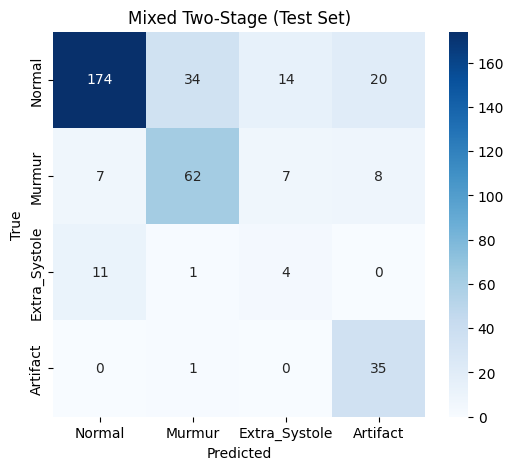


Overall accuracy: 0.7275
Compare against weighted ensemble: accuracy 0.78, Extra_Systole f1 0.29


In [68]:
# Stage 1 decides Normal/Abnormal using the deep CNN
stage1_preds = np.argmax(model_stage1_deep.predict(X_test), axis=1)

# Stage 2: for abnormal-flagged samples, use YAMNet's full 4-class head,
# then pick the best among just the 3 abnormal classes (indices 1,2,3)
final_preds_mixed = np.zeros(len(X_test), dtype=int)
abnormal_indices = np.where(stage1_preds == 1)[0]

if len(abnormal_indices) > 0:
    yamnet_probs_sub = model_yamnet.predict(X_test_yamnet[abnormal_indices])
    # restrict to abnormal classes only (1,2,3), then map back
    abnormal_class_probs = yamnet_probs_sub[:, 1:4]
    sub_preds = np.argmax(abnormal_class_probs, axis=1) + 1  # +1 to map back to original indices
    final_preds_mixed[abnormal_indices] = sub_preds

print("=" * 55)
print(" MIXED TWO-STAGE: Deep CNN (binary) + YAMNet (subtype)")
print("=" * 55)
print(classification_report(y_test, final_preds_mixed, target_names=CLASSES))

cm_mixed = confusion_matrix(y_test, final_preds_mixed)
plt.figure(figsize=(6, 5))
sns.heatmap(cm_mixed, annot=True, fmt='d', cmap='Blues', xticklabels=CLASSES, yticklabels=CLASSES)
plt.xlabel('Predicted'); plt.ylabel('True')
plt.title('Mixed Two-Stage (Test Set)')
plt.show()

print(f"\nOverall accuracy: {np.mean(final_preds_mixed == y_test):.4f}")
print("Compare against weighted ensemble: accuracy 0.78, Extra_Systole f1 0.29")

## 18. Stacking: Learn the optimal combination instead of hand-picking a weight

Rather than guessing a fixed blend ratio (like 0.95/0.05), stacking trains
a small classifier whose inputs are the CNN's and YAMNet's predicted
probabilities (8 numbers per sample), letting it learn the best way to
combine them. Trained on VALIDATION set predictions, evaluated on TEST --
training it on test predictions would be data leakage.

In [76]:
from sklearn.linear_model import LogisticRegression

# Alignment check, same discipline as the test-set ensemble
assert np.array_equal(y_val, y_val_yamnet), "Val set order mismatch between CNN and YAMNet arrays!"
print("Alignment check passed -- y_val and y_val_yamnet match exactly.")

probs_cnn_val = model_deep_cnn.predict(X_val)
probs_yamnet_val = model_yamnet.predict(X_val_yamnet)

# Stack both models' probabilities into one 8-dim feature vector per sample
stacking_features_val = np.concatenate([probs_cnn_val, probs_yamnet_val], axis=1)
print("Stacking feature shape (val):", stacking_features_val.shape)

Alignment check passed -- y_val and y_val_yamnet match exactly.
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
Stacking feature shape (val): (342, 8)


In [77]:
stacking_model = LogisticRegression(
    max_iter=1000,
    class_weight={0: 1, 1: 1, 2: 3, 3: 1.5}
)
stacking_model.fit(stacking_features_val, y_val)
print("Stacking model trained on validation-set predictions (manual mid-weight).")

Stacking model trained on validation-set predictions (manual mid-weight).


 STACKED ENSEMBLE (learned combination)
               precision    recall  f1-score   support

       Normal       0.75      0.92      0.83       242
       Murmur       0.74      0.37      0.49        84
Extra_Systole       0.00      0.00      0.00        16
     Artifact       0.86      0.86      0.86        36

     accuracy                           0.75       378
    macro avg       0.59      0.54      0.55       378
 weighted avg       0.73      0.75      0.72       378



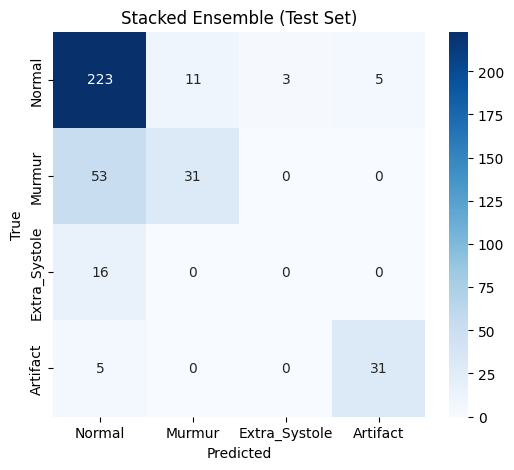


Overall accuracy: 0.7540
Compare against hand-picked weighted ensemble: accuracy 0.78, Extra_Systole f1 0.29


In [78]:
stacking_features_test = np.concatenate([probs_cnn, probs_yamnet], axis=1)
stacking_preds = stacking_model.predict(stacking_features_test)

print("=" * 55)
print(" STACKED ENSEMBLE (learned combination)")
print("=" * 55)
print(classification_report(y_test, stacking_preds, target_names=CLASSES))

cm_stack = confusion_matrix(y_test, stacking_preds)
plt.figure(figsize=(6, 5))
sns.heatmap(cm_stack, annot=True, fmt='d', cmap='Blues', xticklabels=CLASSES, yticklabels=CLASSES)
plt.xlabel('Predicted'); plt.ylabel('True')
plt.title('Stacked Ensemble (Test Set)')
plt.show()

print(f"\nOverall accuracy: {np.mean(stacking_preds == y_test):.4f}")
print("Compare against hand-picked weighted ensemble: accuracy 0.78, Extra_Systole f1 0.29")